MODEL EVALUATION

In `02_data_prep_and_model_selection.ipynb` we picked the tuned XGBoost model using 5-fold cross-validation on the training set. This notebook answers the question: **how well does it do on data it has never seen?**

The test set (1,000 customers, 20% of the data) has been untouched until now. We use it **once**. If we went back and tweaked the model after seeing these results, the test set would become part of model selection and its score would no longer be an honest estimate.

IMPORTING PACKAGES

In [1]:
import numpy as np
import pandas as pd
import joblib
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, recall_score, precision_score, accuracy_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)

# Colours used in every chart: blue = stayed, orange = churned
STAYED_COLOR, CHURNED_COLOR = '#2a78d6', '#eb6834'

LOADING DATA AND RECREATING THE TEST SET

We rebuild exactly the same split as in notebook 02: same cleaning, same features, same `test_size`, `stratify` and `random_state`. With identical input and the same `random_state`, `train_test_split` returns exactly the same rows, so we don't need to save the test set to a file.

The final model was trained on `X_train` only. We recreate `X_train` here just to check that the split matches (4,000 / 1,000 rows, 50.3% churn).

In [2]:
df = pd.read_csv('../src/netflix_customer_churn.csv')

# Same cleaning as notebook 02
df = df.dropna(subset=['churned']).drop_duplicates()
y = df['churned']
X = df.drop(columns=['churned'])

categorical_columns = ['subscription_type', 'payment_method']
numeric_columns = ['last_login_days', 'number_of_profiles', 'avg_watch_time_per_day']
for col in categorical_columns:
    X[col] = X[col].astype('category')
for col in numeric_columns:
    X[col] = pd.to_numeric(X[col], errors='coerce')

X = X[numeric_columns + categorical_columns]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print(f'Train: {X_train.shape[0]} rows, churn rate {y_train.mean():.1%}')
print(f'Test:  {X_test.shape[0]} rows, churn rate {y_test.mean():.1%}')

Train: 4000 rows, churn rate 50.3%
Test:  1000 rows, churn rate 50.3%


LOADING THE FINAL MODEL

`final_model.joblib` is the full pipeline (preprocessing + tuned XGBoost) that `RandomizedSearchCV` refitted on the whole training set. Because the preprocessing is inside the pipeline, we can feed it the raw test columns directly.

In [3]:
final_model = joblib.load('../models/final_model.joblib')
final_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](5,)","['last_login_days','number_of_profiles','avg_watch_time_per_day', 'subscription_type','payment_method']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,5
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('uniform', ...), ('skewed', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).

PREDICTING ON THE TEST SET

The model gives two kinds of output:
- `predict_proba` the **probability** of churn (0 to 1) for each customer. ROC AUC uses these, because it measures how well churners are *ranked* above non-churners.
- `predict` a **yes/no** label, using a threshold of 0.5 (probability ≥ 0.5 → churn). Recall, precision and accuracy use these.

In [6]:
y_proba = final_model.predict_proba(X_test)[:, 1]
y_pred = final_model.predict(X_test)

TEST SCORES VS CROSS-VALIDATION SCORES

The cross-validation scores come from notebook 02 (`xgb_tuned` row in `show_results()`). If the test scores are close to them, the model generalises well. A clear drop would mean we overfitted during tuning, for example because we picked the best of 40 combinations partly by luck.

We add two metrics we didn't use for model selection:
- **Precision**: of the customers we flag as churners, how many actually churn? Low precision means retention budget is wasted on customers who would have stayed.
- **F1**: the balance between recall and precision in one number.

In [7]:
cv_scores = {'roc_auc': 0.999, 'recall': 0.979, 'accuracy': 0.981}   # from notebook 02

test_scores = {
    'roc_auc':   roc_auc_score(y_test, y_proba),
    'recall':    recall_score(y_test, y_pred),
    'accuracy':  accuracy_score(y_test, y_pred)
}

comparison = pd.DataFrame({'cross-validation': cv_scores, 'test': test_scores})
comparison['difference'] = comparison['test'] - comparison['cross-validation']
comparison.round(3)

,cross-validation,test,difference
roc_auc,0.999,0.999,-0.000
recall,0.979,0.974,-0.005
accuracy,0.981,0.981,0.000


CONFUSION MATRIX

The confusion matrix shows the four possible outcomes at threshold 0.5:

| | predicted stay | predicted churn |
|---|---|---|
| **actually stayed** | true negative | false positive (wasted retention offer) |
| **actually churned** | false negative (missed churner) | true positive (caught churner) |

For churn, false negatives are usually the expensive mistake: a customer leaves without us trying to keep them.

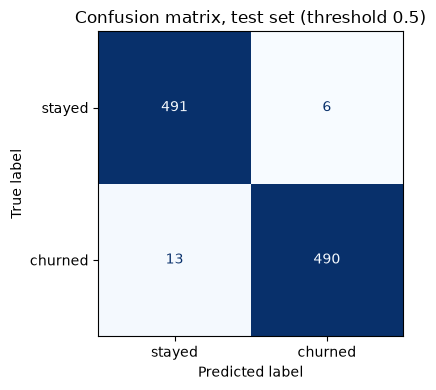

Caught churners (TP): 490   Missed churners (FN): 13
Wasted offers (FP):   6   Correctly left alone (TN): 491


In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['stayed', 'churned'],
    cmap='Blues', colorbar=False, ax=ax,
)
ax.set_title('Confusion matrix, test set (threshold 0.5)')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
print(f'Caught churners (TP): {tp}   Missed churners (FN): {fn}')
print(f'Wasted offers (FP):   {fp}   Correctly left alone (TN): {tn}')

ROC AND PRECISION-RECALL CURVES

Both curves show the model at **every** possible threshold, not just 0.5.
- **ROC curve**: true positive rate (recall) against false positive rate. The closer the curve hugs the top-left corner, the better. The dashed diagonal is a model that guesses randomly (AUC 0.5).
- **Precision-recall curve**: what precision we keep as we push recall higher. Useful when deciding on a threshold.

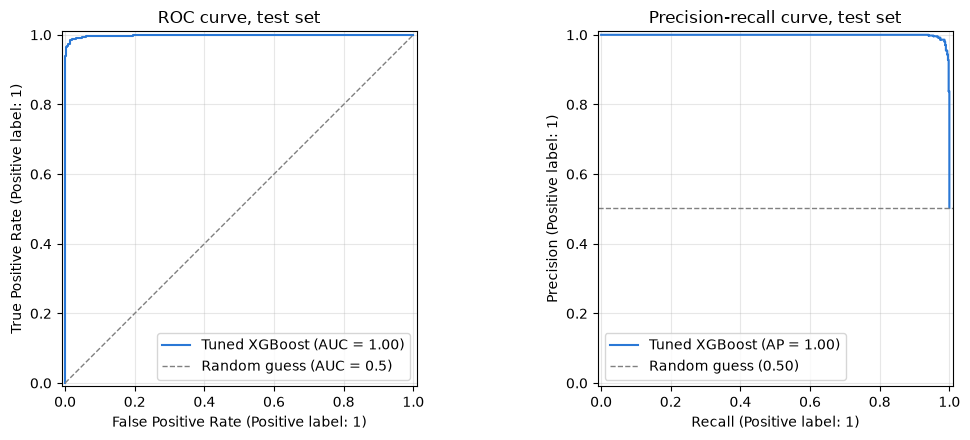

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

RocCurveDisplay.from_predictions(y_test, y_proba, name='Tuned XGBoost', ax=axes[0])
axes[0].lines[0].set_color(STAYED_COLOR)
axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey', linewidth=1, label='Random guess (AUC = 0.5)')
axes[0].set_title('ROC curve, test set')
axes[0].legend(loc='lower right')

PrecisionRecallDisplay.from_predictions(y_test, y_proba, name='Tuned XGBoost', ax=axes[1])
axes[1].lines[0].set_color(STAYED_COLOR)
axes[1].axhline(y_test.mean(), linestyle='--', color='grey', linewidth=1, label=f'Random guess ({y_test.mean():.2f})')
axes[1].set_title('Precision-recall curve, test set')
axes[1].legend(loc='lower left')

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

PREDICTED PROBABILITIES

How confident is the model? Ideally churners get probabilities close to 1, stayers close to 0, and very few customers end up in the middle. The customers in the middle are the ones where the choice of threshold matters.

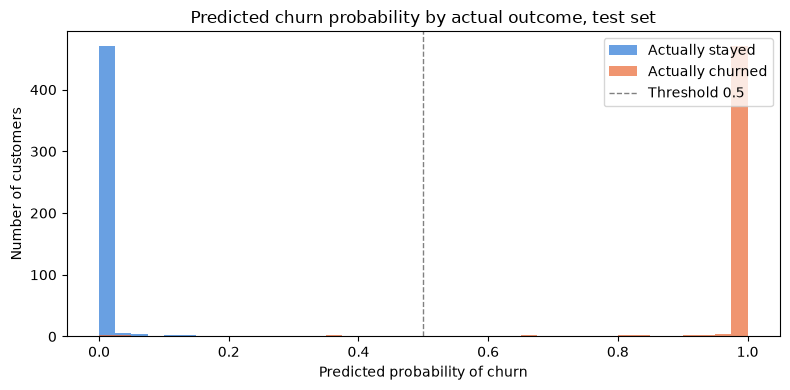

Customers with a probability between 0.2 and 0.8: 18 of 1000


In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.linspace(0, 1, 41)
ax.hist(y_proba[y_test == 0], bins=bins, color=STAYED_COLOR, alpha=0.7, label='Actually stayed')
ax.hist(y_proba[y_test == 1], bins=bins, color=CHURNED_COLOR, alpha=0.7, label='Actually churned')
ax.axvline(0.5, linestyle='--', color='grey', linewidth=1, label='Threshold 0.5')
ax.set_xlabel('Predicted probability of churn')
ax.set_ylabel('Number of customers')
ax.set_title('Predicted churn probability by actual outcome, test set')
ax.legend()
plt.tight_layout()
plt.show()

uncertain = ((y_proba > 0.2) & (y_proba < 0.8)).sum()
print(f'Customers with a probability between 0.2 and 0.8: {uncertain} of {len(y_proba)}')

CHOOSING A THRESHOLD

0.5 is only the default. The right threshold depends on the business trade-off:
- **Lower threshold** → more customers flagged → higher recall (fewer missed churners), but lower precision (more offers to people who would have stayed).
- **Higher threshold** → fewer customers flagged → higher precision, but more churners slip through.

The table below shows that trade-off on the test set. If a retention offer is cheap compared to losing a customer, a lower threshold is usually worth it.

Strictly speaking, choosing a threshold is also a modelling decision, so it should be made on validation data rather than the test set. Here we use the table to *understand* the trade-off; a final threshold would be set with cross-validated predictions on the training set (`cross_val_predict`).

In [11]:
thresholds = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rows = []
for t in thresholds:
    pred_t = (y_proba >= t).astype(int)
    rows.append({
        'threshold': t,
        'flagged customers': int(pred_t.sum()),
        'recall': recall_score(y_test, pred_t),
        'precision': precision_score(y_test, pred_t, zero_division=0),
        'missed churners': int(((pred_t == 0) & (y_test == 1)).sum()),
        'wasted offers': int(((pred_t == 1) & (y_test == 0)).sum()),
    })

pd.DataFrame(rows).set_index('threshold').round(3)

,flagged customers,recall,precision,missed churners,wasted offers
threshold,,,,,
0.1,513,0.990,0.971,5,15
0.2,504,0.986,0.984,7,8
0.3,503,0.986,0.986,7,7
0.4,499,0.978,0.986,11,7
0.5,496,0.974,0.988,13,6
0.6,494,0.974,0.992,13,4
0.7,490,0.968,0.994,16,3
0.8,486,0.962,0.996,19,2
0.9,480,0.952,0.998,24,1


FINDINGS

_To write after running the notebook:_
- How do the test scores compare with the cross-validation scores? Any sign of overfitting?
- How many churners does the model miss at threshold 0.5, and how many offers are wasted?
- Which threshold would you recommend, and why?
- Reminder of the limitations: synthetic data, `last_login_days` kept despite the leakage question (see notebook 02), scores this high are unusual for real churn data.